In [3]:
import pandas as pd

df1 = pd.read_csv("dataset1.csv", encoding="cp1252")

In [4]:
df1 = pd.read_csv("dataset1.csv", encoding="latin1")

In [5]:
df1.head()
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   SI                        149 non-null    int64  
 1   Date & Time               149 non-null    str    
 2   Solar Power (KW)          149 non-null    str    
 3   Ambient Temperature (°C)  149 non-null    float64
 4   Module Temperature (°C)   149 non-null    float64
dtypes: float64(2), int64(1), str(2)
memory usage: 9.2 KB


In [6]:
%pip install -q pennylane torch scikit-learn pandas numpy matplotlib


Note: you may need to restart the kernel to use updated packages.


In [7]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import pennylane as qml
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cpu')  # PennyLane default.qubit is CPU based
print('Torch:', torch.__version__, '| PennyLane:', qml.__version__, '| Device:', DEVICE)


Torch: 2.15.0 | PennyLane: 0.45.1 | Device: cpu


In [8]:
DATA_PATH = '/Users/sahilanant/Downloads/abha_july_zero_filled_similar_values (1).csv'
# If using another file, update DATA_PATH. The June file is too sparse for 5-minute forecasts.

df = pd.read_csv(DATA_PATH, encoding='cp1252')
df.columns = df.columns.str.strip()
df['Date & Time'] = pd.to_datetime(df['Date & Time'], format='%d-%m-%Y %H:%M', errors='coerce')
df = df.dropna(subset=['Date & Time']).sort_values('Date & Time').drop_duplicates('Date & Time').set_index('Date & Time')
print('Rows:', len(df), '| from', df.index.min(), 'to', df.index.max())
print('Columns:', df.columns.tolist())
display(df.head())
print('Most common sampling gaps:')
display(df.index.to_series().diff().value_counts().head())


Rows: 4835 | from 2024-07-01 06:00:00 to 2024-07-31 18:55:00
Columns: ['Solar Power (KW)', 'Solar Current (A)', 'Tilted Radiation (W/m2)', 'Ambient Temperature', 'Module Temperature']


,Solar Power (KW),Solar Current (A),Tilted Radiation (W/m2),Ambient Temperature,Module Temperature
Date & Time,,,,,
2024-07-01 06:00:00,4.30,55.26,3.72,24.08,24.73
2024-07-01 06:05:00,5.39,54.53,4.87,24.13,24.63
2024-07-01 06:10:00,7.15,55.51,5.78,24.32,24.74
2024-07-01 06:15:00,10.09,53.26,6.76,24.20,24.89
2024-07-01 06:20:00,12.18,53.89,7.61,24.01,24.75


Most common sampling gaps:


Date & Time
0 days 00:05:00    4803
0 days 11:05:00      30
0 days 00:10:00       1
Name: count, dtype: int64

In [9]:
TARGET = 'Solar Power (KW)'
base_features = ['Solar Power (KW)', 'Solar Current (A)', 'Tilted Radiation (W/m2)', 'Ambient Temperature', 'Module Temperature']
missing = [c for c in base_features if c not in df.columns]
if missing:
    raise ValueError(f'Missing expected columns: {missing}. Update base_features to match your CSV.')

# Numeric cleanup, then keep only contiguous 5-minute runs (no window crosses an overnight/data gap).
for c in base_features:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df[base_features] = df[base_features].replace([np.inf, -np.inf], np.nan)
df[base_features] = df[base_features].interpolate(method='time', limit=2).ffill(limit=2).bfill(limit=2)
df = df.dropna(subset=base_features)

# Treat negative generation values as invalid if present; zero output at night remains valid.
df = df[df[TARGET] >= 0]
delta = df.index.to_series().diff()
group_id = delta.ne(pd.Timedelta(minutes=5)).cumsum()
# The first row starts its own segment.
segments = [g.copy() for _, g in df.groupby(group_id) if len(g) >= 15]
print('Continuous 5-minute segments:', len(segments), '| usable rows:', sum(map(len, segments)))

# Add cyclic clock features.
for seg in segments:
    mins = seg.index.hour * 60 + seg.index.minute
    seg['tod_sin'] = np.sin(2*np.pi*mins/1440)
    seg['tod_cos'] = np.cos(2*np.pi*mins/1440)
    doy = seg.index.dayofyear
    seg['doy_sin'] = np.sin(2*np.pi*doy/366)
    seg['doy_cos'] = np.cos(2*np.pi*doy/366)
FEATURES = base_features + ['tod_sin','tod_cos','doy_sin','doy_cos']
LOOKBACK = 12
HORIZONS = [1, 2, 3]  # 5, 10, 15 minutes

# Global chronological boundaries. Windows must have input and all targets within the same split.
all_times = df.index.sort_values().unique()
t1, t2 = all_times[int(.70*len(all_times))], all_times[int(.85*len(all_times))]
print('Train/validation/test cutoffs:', t1, t2)


Continuous 5-minute segments: 32 | usable rows: 4835
Train/validation/test cutoffs: 2024-07-22 15:05:00 2024-07-27 10:30:00


In [10]:
# Fit scalers only from training-period rows.
train_rows = df.loc[df.index < t1, base_features].copy()
feature_scaler = StandardScaler().fit(train_rows[base_features])
target_scaler = StandardScaler().fit(train_rows[[TARGET]])

X_parts, y_parts, t_parts = {'train':[], 'val':[], 'test':[]}, {'train':[], 'val':[], 'test':[]}, {'train':[], 'val':[], 'test':[]}

def split_name(t):
    if t < t1: return 'train'
    if t < t2: return 'val'
    return 'test'

for seg in segments:
    feat = seg[base_features].copy()
    feat[base_features] = feature_scaler.transform(feat[base_features])
    feat[['tod_sin','tod_cos','doy_sin','doy_cos']] = seg[['tod_sin','tod_cos','doy_sin','doy_cos']].values
    power_scaled = target_scaler.transform(seg[[TARGET]]).ravel()
    times = seg.index
    values = feat[FEATURES].to_numpy(dtype=np.float32)
    for i in range(LOOKBACK, len(seg)-max(HORIZONS)+1):
        input_time = times[i-1]
        target_times = times[[i+h-1 for h in HORIZONS]]
        split = split_name(target_times[-1])
        # Do not allow a sample to straddle a chronological split.
        if any(split_name(t) != split for t in target_times) or split_name(input_time) != split:
            continue
        X_parts[split].append(values[i-LOOKBACK:i])
        y_parts[split].append(power_scaled[[i+h-1 for h in HORIZONS]])
        t_parts[split].append(target_times.to_numpy())

for s in X_parts:
    X_parts[s] = np.asarray(X_parts[s], dtype=np.float32)
    y_parts[s] = np.asarray(y_parts[s], dtype=np.float32)
    t_parts[s] = np.asarray(t_parts[s])
    print(s, X_parts[s].shape, y_parts[s].shape)
if min(len(X_parts['train']),len(X_parts['val']),len(X_parts['test'])) == 0:
    raise ValueError('A split has no sequences. Check date spacing or use a larger contiguous dataset.')


train (3062, 12, 9) (3062, 3)
val (652, 12, 9) (652, 3)
test (667, 12, 9) (667, 3)


In [11]:
N_QUBITS = 4
qdev = qml.device('default.qubit', wires=N_QUBITS)

@qml.qnode(qdev, interface='torch', diff_method='backprop')
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation='Y')
    qml.BasicEntanglerLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

weight_shapes = {'weights': (2, N_QUBITS)}
quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)

class HQLSTM(nn.Module):
    def __init__(self, n_features, quantum=True):
        super().__init__()
        self.lstm = nn.LSTM(n_features, 16, batch_first=True)
        self.pre = nn.Linear(16, N_QUBITS)
        self.quantum = quantum
        self.q_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes) if quantum else None
        self.head = nn.Linear(N_QUBITS, len(HORIZONS))
    def forward(self, x):
        z, _ = self.lstm(x)
        z = torch.tanh(self.pre(z[:, -1, :])) * np.pi
        if self.quantum: z = self.q_layer(z)
        return self.head(z)

class HQCNN(nn.Module):
    def __init__(self, n_features, quantum=True):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(n_features, 16, 3, padding=1), nn.ReLU(),
                                  nn.Conv1d(16, 16, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        self.pre = nn.Linear(16, N_QUBITS)
        self.quantum = quantum
        self.q_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes) if quantum else None
        self.head = nn.Linear(N_QUBITS, len(HORIZONS))
    def forward(self, x):
        z = self.conv(x.transpose(1,2)).squeeze(-1)
        z = torch.tanh(self.pre(z)) * np.pi
        if self.quantum: z = self.q_layer(z)
        return self.head(z)

n_features = X_parts['train'].shape[-1]
print('Input features:', n_features)


Input features: 9


In [12]:
BATCH_SIZE = 32
EPOCHS = 30
PATIENCE = 6

def loader(split, shuffle=False):
    ds = TensorDataset(torch.tensor(X_parts[split]), torch.tensor(y_parts[split]))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle)

def train_model(model, name):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=0.003)
    loss_fn = nn.MSELoss()
    best, best_state, wait = float('inf'), None, 0
    history = {'train':[], 'val':[]}
    for epoch in range(EPOCHS):
        model.train(); losses=[]
        for xb,yb in loader('train', True):
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            opt.zero_grad(); pred=model(xb); loss=loss_fn(pred,yb); loss.backward(); opt.step(); losses.append(loss.item())
        model.eval(); vals=[]
        with torch.no_grad():
            for xb,yb in loader('val'):
                vals.append(loss_fn(model(xb.to(DEVICE)),yb.to(DEVICE)).item())
        tr, va=float(np.mean(losses)),float(np.mean(vals))
        history['train'].append(tr); history['val'].append(va)
        print(f'{name} epoch {epoch+1:02d}: train={tr:.4f} val={va:.4f}')
        if va < best:
            best=va; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; wait=0
        else:
            wait+=1
            if wait >= PATIENCE: break
    model.load_state_dict(best_state)
    return model, history

models, histories = {}, {}
for name, model in [
    ('HQLSTM', HQLSTM(n_features, quantum=True)),
    ('HQCNN', HQCNN(n_features, quantum=True)),
    ('LSTM baseline', HQLSTM(n_features, quantum=False)),
    ('CNN baseline', HQCNN(n_features, quantum=False)),
]:
    models[name], histories[name] = train_model(model, name)


HQLSTM epoch 01: train=0.6572 val=0.2106
HQLSTM epoch 02: train=0.3422 val=0.1098
HQLSTM epoch 03: train=0.3061 val=0.0902
HQLSTM epoch 04: train=0.3013 val=0.0858
HQLSTM epoch 05: train=0.2991 val=0.0835
HQLSTM epoch 06: train=0.2972 val=0.0921
HQLSTM epoch 07: train=0.2960 val=0.0882
HQLSTM epoch 08: train=0.2941 val=0.0881
HQLSTM epoch 09: train=0.2937 val=0.1110
HQLSTM epoch 10: train=0.2925 val=0.1071
HQLSTM epoch 11: train=0.2904 val=0.0880
HQCNN epoch 01: train=0.8930 val=0.4264
HQCNN epoch 02: train=0.4446 val=0.1715
HQCNN epoch 03: train=0.3471 val=0.1715
HQCNN epoch 04: train=0.3254 val=0.2134
HQCNN epoch 05: train=0.3175 val=0.1198
HQCNN epoch 06: train=0.3174 val=0.2682
HQCNN epoch 07: train=0.3029 val=0.1093
HQCNN epoch 08: train=0.3010 val=0.1451
HQCNN epoch 09: train=0.2961 val=0.1357
HQCNN epoch 10: train=0.2928 val=0.1125
HQCNN epoch 11: train=0.2883 val=0.1040
HQCNN epoch 12: train=0.2884 val=0.1384
HQCNN epoch 13: train=0.2889 val=0.1085
HQCNN epoch 14: train=0.2831 

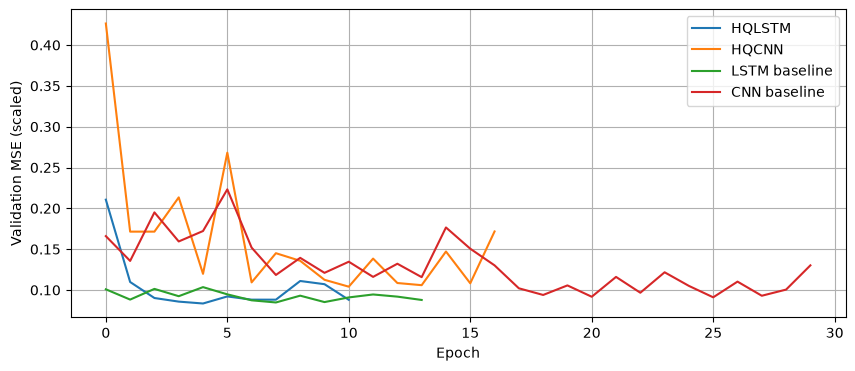

In [13]:
plt.figure(figsize=(10,4))
for name,h in histories.items():
    plt.plot(h['val'], label=name)
plt.xlabel('Epoch'); plt.ylabel('Validation MSE (scaled)'); plt.legend(); plt.grid(True); plt.show()


In [14]:
X_test = torch.tensor(X_parts['test'], dtype=torch.float32)
with torch.no_grad():
    pred_scaled = {name: model.eval()(X_test).cpu().numpy() for name,model in models.items()}
y_true = target_scaler.inverse_transform(y_parts['test'].reshape(-1,1)).reshape(-1,len(HORIZONS))
y_pred = {name: target_scaler.inverse_transform(v.reshape(-1,1)).reshape(-1,len(HORIZONS)) for name,v in pred_scaled.items()}
# persistence: latest measured power in each input window, converted back to kW
power_feature_idx = FEATURES.index(TARGET)
last_power_scaled = X_parts['test'][:, -1, power_feature_idx]
last_power_kw = feature_scaler.mean_[power_feature_idx] + last_power_scaled * feature_scaler.scale_[power_feature_idx]
y_pred['Persistence'] = np.repeat(last_power_kw[:,None], len(HORIZONS), axis=1)

rows=[]
for name,p in y_pred.items():
    for j,mins in enumerate([5,10,15]):
        rows.append({'Model':name,'Horizon (min)':mins,
                     'MAE (kW)':mean_absolute_error(y_true[:,j],p[:,j]),
                     'RMSE (kW)':np.sqrt(mean_squared_error(y_true[:,j],p[:,j])),
                     'R2':r2_score(y_true[:,j],p[:,j])})
metrics = pd.DataFrame(rows)
display(metrics.round(3))


,Model,Horizon (min),MAE (kW),RMSE (kW),R2
0,HQLSTM,5,142.337,242.267,0.742
1,HQLSTM,10,173.915,290.297,0.630
2,HQLSTM,15,192.726,309.324,0.575
3,HQCNN,5,191.835,289.927,0.631
4,HQCNN,10,222.034,327.219,0.530
5,HQCNN,15,230.291,338.519,0.491
6,LSTM baseline,5,136.151,237.160,0.753
7,LSTM baseline,10,174.435,288.447,0.635
8,LSTM baseline,15,192.112,302.744,0.593
9,CNN baseline,5,142.146,229.262,0.769


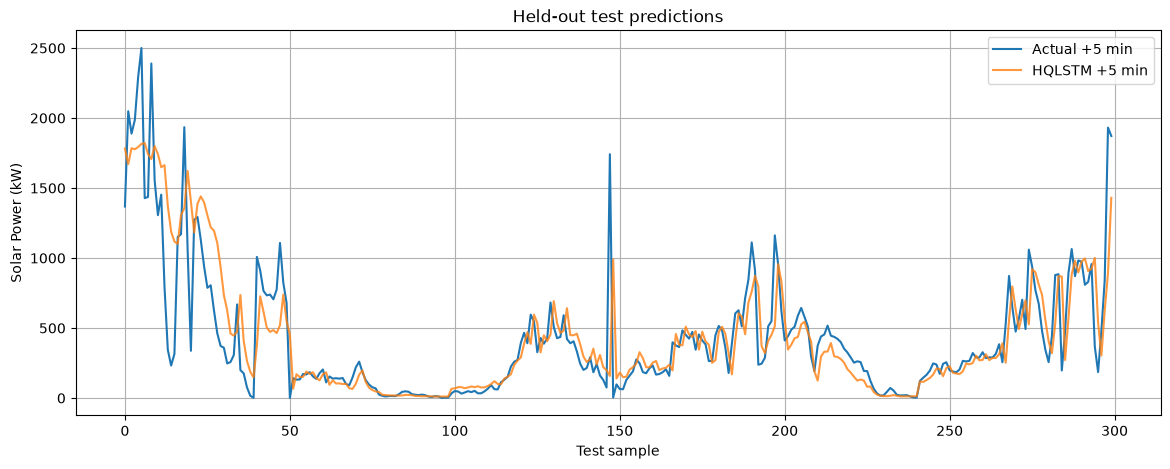

In [15]:
# Plot one selected model on a short test slice. Change model name if desired.
MODEL_TO_PLOT = 'HQLSTM'
plot_n = min(300, len(y_true))
plt.figure(figsize=(14,5))
plt.plot(y_true[:plot_n,0], label='Actual +5 min', linewidth=1.5)
plt.plot(y_pred[MODEL_TO_PLOT][:plot_n,0], label=f'{MODEL_TO_PLOT} +5 min', alpha=.8)
plt.ylabel('Solar Power (kW)'); plt.xlabel('Test sample'); plt.title('Held-out test predictions'); plt.legend(); plt.grid(True); plt.show()


In [16]:
latest_segment = max(segments, key=lambda s: s.index.max())
if len(latest_segment) < LOOKBACK:
    raise ValueError('Need at least 12 consecutive 5-minute rows for the latest forecast window.')
recent = latest_segment.iloc[-LOOKBACK:].copy()
recent_features = recent[base_features].copy()
recent_features[base_features] = feature_scaler.transform(recent_features)
mins = recent.index.hour*60 + recent.index.minute
doy = recent.index.dayofyear
recent_features['tod_sin'] = np.sin(2*np.pi*mins/1440)
recent_features['tod_cos'] = np.cos(2*np.pi*mins/1440)
recent_features['doy_sin'] = np.sin(2*np.pi*doy/366)
recent_features['doy_cos'] = np.cos(2*np.pi*doy/366)
x_live = torch.tensor(recent_features[FEATURES].to_numpy(dtype=np.float32)[None,:,:])
forecast_rows=[]
last_time=recent.index[-1]
for name,model in models.items():
    model.eval()
    with torch.no_grad():
        pred_s=model(x_live).cpu().numpy().reshape(-1,1)
    pred_kw=target_scaler.inverse_transform(pred_s).ravel()
    for horizon,kw in zip([5,10,15],pred_kw):
        forecast_rows.append({'Model':name,'Forecast time':last_time+pd.Timedelta(minutes=horizon),'Minutes ahead':horizon,'Predicted power (kW)':max(0.0,float(kw))})
forecast = pd.DataFrame(forecast_rows)
display(forecast.pivot(index='Minutes ahead',columns='Model',values='Predicted power (kW)').round(2))


Model,CNN baseline,HQCNN,HQLSTM,LSTM baseline
Minutes ahead,,,,
5,0.0,1.28,10.06,0.00
10,0.0,12.04,38.44,0.00
15,0.0,5.50,77.69,10.58


In [17]:
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# अपनी CSV का सही path डालें
TEST_PATH = "/Users/sahilanant/Documents/Codex/2026-11-24/wh/outputs/solar_pv_test_samples.csv"

test_df = pd.read_csv(TEST_PATH, parse_dates=["Input end time"])

# ये नाम training notebook में भी इस्तेमाल हुए थे
base_features = [
    "Solar Power (KW)",
    "Solar Current (A)",
    "Tilted Radiation (W/m2)",
    "Ambient Temperature",
    "Module Temperature",
]
lookback = 12
horizons = [5, 10, 15]

# Test CSV से 12 readings का model input बनाएँ
X_test_raw = np.zeros((len(test_df), lookback, len(FEATURES)), dtype=np.float32)

for row_i, row in test_df.iterrows():
    end_time = row["Input end time"]

    for step in range(lookback):
        minutes_ago = (lookback - 1 - step) * 5
        time_label = f"t-{minutes_ago:02d}m"

        # मूल sensor readings
        raw_values = np.array(
            [[row[f"{time_label} {feature}"] for feature in base_features]],
            dtype=float
        )
        scaled_values = feature_scaler.transform(raw_values)[0]

        # समय की cyclical features
        sample_time = end_time - pd.Timedelta(minutes=minutes_ago)
        minute_of_day = sample_time.hour * 60 + sample_time.minute
        day_of_year = sample_time.dayofyear

        time_values = [
            np.sin(2 * np.pi * minute_of_day / 1440),
            np.cos(2 * np.pi * minute_of_day / 1440),
            np.sin(2 * np.pi * day_of_year / 366),
            np.cos(2 * np.pi * day_of_year / 366),
        ]

        X_test_raw[row_i, step, :] = np.concatenate([scaled_values, time_values])

# Actual target values: +5, +10 और +15 मिनट
y_true = test_df[
    [f"Actual +{h} min power (kW)" for h in horizons]
].to_numpy(dtype=float)

# हर trained model से prediction लें
X_tensor = torch.tensor(X_test_raw, dtype=torch.float32)
predictions = {}

for model_name, model in models.items():
    model.eval()
    with torch.no_grad():
        pred_scaled = model(X_tensor).cpu().numpy()

    # scaled predictions को वापस kW में बदलें
    predictions[model_name] = target_scaler.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).reshape(-1, len(horizons))

# Metrics दिखाएँ
results = []

for model_name, y_pred in predictions.items():
    for j, minutes in enumerate(horizons):
        results.append({
            "Model": model_name,
            "Forecast (minutes ahead)": minutes,
            "MAE (kW)": mean_absolute_error(y_true[:, j], y_pred[:, j]),
            "RMSE (kW)": np.sqrt(mean_squared_error(y_true[:, j], y_pred[:, j])),
            "R²": r2_score(y_true[:, j], y_pred[:, j]),
        })

results_df = pd.DataFrame(results)
display(results_df.round(3))

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.14/

,Model,Forecast (minutes ahead),MAE (kW),RMSE (kW),R²
0,HQLSTM,5,142.193,242.092,0.745
1,HQLSTM,10,174.082,290.290,0.631
2,HQLSTM,15,192.944,309.370,0.581
3,HQCNN,5,191.629,289.717,0.635
4,HQCNN,10,222.315,327.357,0.531
5,HQCNN,15,230.385,338.455,0.499
6,LSTM baseline,5,135.975,236.984,0.756
7,LSTM baseline,10,174.793,288.675,0.635
8,LSTM baseline,15,192.314,302.782,0.599
9,CNN baseline,5,142.000,229.096,0.772


In [18]:
raw_values = pd.DataFrame(
    [[row[f"{time_label} {feature}"] for feature in base_features]],
    columns=base_features
)
scaled_values = feature_scaler.transform(raw_values)[0]

In [20]:
%pip install streamlit plotly

Note: you may need to restart the kernel to use updated packages.


In [21]:
!streamlit run dashboard.py

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: dashboard.py


In [22]:
import os, sys
print("Notebook folder:", os.getcwd())
print("Python:", sys.executable)
print("dashboard.py मिला:", os.path.exists("dashboard.py"))

Notebook folder: /Users/sahilanant/solar power forecasting /datasets 
Python: /opt/anaconda3/bin/python
dashboard.py मिला: False


In [23]:
%cd ..

/Users/sahilanant/solar power forecasting 


In [24]:
import os
print(os.path.exists("dashboard.py"))

True


In [ ]:
import sys
!{sys.executable} -m streamlit run dashboard.py

In [ ]:
import urllib.request

try:
    response = urllib.request.urlopen("http://localhost:8501", timeout=3)
    print("Streamlit server चल रहा है। Status:", response.status)
except Exception as e:
    print("Streamlit server से connection नहीं हुआ:", repr(e))

In [ ]:
import urllib.request

try:
    response = urllib.request.urlopen("http://localhost:8501", timeout=3)
    print("Streamlit server चल रहा है। Status:", response.status)
except Exception as e:
    print("Streamlit server से connection नहीं हुआ:", repr(e))

In [ ]:
import os
import sys
import subprocess

log_file = open("streamlit.log", "w")
process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        os.path.abspath("dashboard.py"),
        "--server.port", "8501",
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True,
)

print("Streamlit शुरू किया। Process ID:", process.pid)
print("Browser में खोलें: http://localhost:8501")

In [1]:
import os, sys, subprocess

print("dashboard.py मौजूद है:", os.path.exists("dashboard.py"))
print("Streamlit install है:", subprocess.run(
    [sys.executable, "-m", "streamlit", "--version"],
    capture_output=True, text=True
).stdout)


dashboard.py मौजूद है: False
Streamlit install है: Streamlit, version 1.58.0



In [2]:
from pathlib import Path

current = Path.cwd()
print("Notebook folder:", current)

matches = list(current.parent.rglob("dashboard.py"))
print("dashboard.py files found:")
for path in matches:
    print(path)

Notebook folder: /Users/sahilanant/solar power forecasting /datasets 
dashboard.py files found:
/Users/sahilanant/solar power forecasting /dashboard.py


In [3]:
import sys
import time
import subprocess

app_path = "/Users/sahilanant/solar power forecasting /dashboard.py"

with open("/tmp/streamlit.log", "w") as log:
    process = subprocess.Popen(
        [
            sys.executable, "-m", "streamlit", "run", app_path,
            "--server.address", "127.0.0.1",
            "--server.port", "8501",
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        start_new_session=True,
    )

time.sleep(3)
print("Streamlit process ID:", process.pid)
print(open("/tmp/streamlit.log").read()[-2000:])

Streamlit process ID: 66151

      👋 Welcome to Streamlit!

      If you'd like to receive helpful onboarding emails, news, offers, promotions,
      and the occasional swag, please enter your email address below. Otherwise,
      leave this field blank.

      Email: 2026-11-24 13:55:55.471 



In [5]:
import os
import sys
import time
import subprocess

# पिछली कोशिश का process रोकें, अगर अभी चल रहा है
try:
    if process.poll() is None:
        process.terminate()
        process.wait(timeout=5)
except Exception:
    pass

app_path = "/Users/sahilanant/solar power forecasting /dashboard.py"
env = os.environ.copy()
env["STREAMLIT_BROWSER_GATHER_USAGE_STATS"] = "false"

with open("/tmp/streamlit.log", "w") as log:
    process = subprocess.Popen(
        [
            sys.executable, "-m", "streamlit", "run", app_path,
            "--server.headless", "true",
            "--server.address", "127.0.0.1",
            "--server.port", "8501",
        ],
        stdin=subprocess.DEVNULL,
        stdout=log,
        stderr=subprocess.STDOUT,
        env=env,
        start_new_session=True,
    )

time.sleep(5)
print("Process status:", process.poll())  # None का मतलब process अभी चल रहा है
print(open("/tmp/streamlit.log").read()[-3000:])

Process status: None
2026-11-24 14:11:01.486 Uvicorn server started on 127.0.0.1:8501

  You can now view your Streamlit app in your browser.

  URL: http://127.0.0.1:8501




In [6]:
%cd "/Users/sahilanant/solar power forecasting "
!pwd
!git status --short --branch

/Users/sahilanant/solar power forecasting 
/Users/sahilanant/solar power forecasting 
fatal: not a git repository (or any of the parent directories): .git


In [7]:
!git init -b main

Initialized empty Git repository in /Users/sahilanant/solar power forecasting /.git/


In [8]:
!git remote -v

In [9]:
!git remote add origin https://github.com/sahilkumaranant22-ui/solar-power-forecasting.git

In [10]:
!git add "*.py" "*.ipynb"
!git status --short

A  .ipynb_checkpoints/dashboard-checkpoint.py
A  dashboard.py
A  "datasets /.ipynb_checkpoints/Untitled-checkpoint.ipynb"
A  "datasets /Untitled.ipynb"
A  "note book /.ipynb_checkpoints/code-checkpoint.ipynb"
A  "note book /code.ipynb"
?? "datasets /dataset1.csv"
?? "datasets /dataset2.csv"


In [11]:
!git restore --staged -- ".ipynb_checkpoints/dashboard-checkpoint.py" "datasets /.ipynb_checkpoints/Untitled-checkpoint.ipynb" "note book /.ipynb_checkpoints/code-checkpoint.ipynb"
!git add -- dashboard.py "datasets /Untitled.ipynb" "note book /code.ipynb"
!git status --short

fatal: could not resolve 'HEAD'
A  .ipynb_checkpoints/dashboard-checkpoint.py
A  dashboard.py
A  "datasets /.ipynb_checkpoints/Untitled-checkpoint.ipynb"
A  "datasets /Untitled.ipynb"
A  "note book /.ipynb_checkpoints/code-checkpoint.ipynb"
A  "note book /code.ipynb"
?? "datasets /dataset1.csv"
?? "datasets /dataset2.csv"


In [12]:
!git rm --cached -r .
!git add -- dashboard.py "datasets /Untitled.ipynb" "note book /code.ipynb"
!git status --short

error: the following file has staged content different from both the
file and the HEAD:
    datasets /Untitled.ipynb
(use -f to force removal)
A  .ipynb_checkpoints/dashboard-checkpoint.py
A  dashboard.py
A  "datasets /.ipynb_checkpoints/Untitled-checkpoint.ipynb"
A  "datasets /Untitled.ipynb"
A  "note book /.ipynb_checkpoints/code-checkpoint.ipynb"
A  "note book /code.ipynb"
?? "datasets /dataset1.csv"
?? "datasets /dataset2.csv"


In [13]:
!git rm --cached -f -- ".ipynb_checkpoints/dashboard-checkpoint.py" "datasets /.ipynb_checkpoints/Untitled-checkpoint.ipynb" "note book /.ipynb_checkpoints/code-checkpoint.ipynb"
!git status --short

rm '.ipynb_checkpoints/dashboard-checkpoint.py'
rm 'datasets /.ipynb_checkpoints/Untitled-checkpoint.ipynb'
rm 'note book /.ipynb_checkpoints/code-checkpoint.ipynb'
A  dashboard.py
AM "datasets /Untitled.ipynb"
A  "note book /code.ipynb"
?? .ipynb_checkpoints/
?? "datasets /.ipynb_checkpoints/"
?? "datasets /dataset1.csv"
?? "datasets /dataset2.csv"
?? "note book /.ipynb_checkpoints/"


In [14]:
!git commit -m "Add solar forecasting project"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'sahilanant@Mac.(none)')


In [16]:
git config --global user.email "sahilkumaranant22@gmail.com"
git config --global user.name "sahil anant"


SyntaxError: invalid syntax (2790623991.py, line 1)

In [17]:
!git config --local user.name "sahil anant"
!git config --local user.email "sahilkumaranant22@gmail.com"

In [ ]:
!git status --short